# Reported pedestrian injury collisions: data understanding and preparation

This notebook inspects Department for Transport (DfT) inputs, explores London-wide patterns and prepares auditable collision candidates for later spatial validation. The questions below guide the later borough analysis; this EDA does not establish statistically significant hotspots. The authoritative scope and provisional approach are in the [README research framework](../README.md#research-framework).

**Research questions**

- **Main:** Where are reported pedestrian injury collisions spatially concentrated within the selected London borough during the study period?
- **SQ1:** How does the spatial distribution of qualifying collision counts vary across the borough?
- **SQ2:** Which local concentrations, if any, are statistically significant under the selected spatial test?
- **SQ3:** How sensitive are the identified concentrations to one alternative spatial-analysis setting?

**Status:** all 14 code cells have saved execution counts in sequence, with no saved errors and four EDA figures. The export reports 74,682 national candidates, including 17,596 recorded-London and 17 Heathrow-coded collisions. Coordinate consistency, boundary membership and final study-scope decisions remain unresolved.

## Task 1: Data understanding and EDA

### 1.1 Working directory and inputs

Run from `notebooks/` using the project `.venv` and dependencies in `../requirements.txt`. Inputs default to `../data`; set `DATA_DIR` or `COMP1890_DATA_DIR` for another location. Source files remain unchanged; Task 2 writes derived candidates and an audit log.

In [1]:
from pathlib import Path
import hashlib
import json
import os
import platform

import pandas as pd
from IPython.display import display

DATA_DIR = Path(os.environ.get("COMP1890_DATA_DIR", "../data")).expanduser()
YEARS = (2022, 2023, 2024, 2025)
GUIDE_NAME = "dft-road-casualty-statistics-road-safety-open-dataset-data-guide-2025.xlsx"

if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        "Input directory not found. Run from the notebook folder and set DATA_DIR "
        "or COMP1890_DATA_DIR to the supplied input directory."
    )
print({"python": platform.python_version(), "pandas": pd.__version__})

OUTPUT_DIR = Path(os.environ.get("COMP1890_OUTPUT_DIR", "../data/derived")).expanduser()
GRID_CRS = "EPSG:27700"
# Extents: (minimum x, minimum y, maximum x, maximum y); flags only.
LONDON_GRID_EXTENT = None
LONDON_LONLAT_EXTENT = None
LONDON_EXTENT_SOURCE = ""
if (LONDON_GRID_EXTENT is not None or LONDON_LONLAT_EXTENT is not None) and not LONDON_EXTENT_SOURCE.strip():
    raise ValueError("Record LONDON_EXTENT_SOURCE before enabling an extent screen.")


{'python': '3.12.3', 'pandas': '3.1.1'}


### 1.2 File inventory and integrity

Compare the nine downloaded files against the manifest using byte sizes and SHA-256 checksums. Stop on a mismatch before using the records.

In [2]:
manifest_path = DATA_DIR / "download-manifest.json"
if not manifest_path.is_file():
    raise FileNotFoundError("download-manifest.json is missing from the input directory.")
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
entries = {entry["file"]: entry for entry in manifest["files"]}
expected_files = [
    f"dft-road-casualty-statistics-{kind}-{year}.csv"
    for year in YEARS for kind in ("collision", "casualty")
] + [GUIDE_NAME]
required_files = expected_files
checks = []
for name in expected_files:
    path = DATA_DIR / name
    if not path.is_file() or name not in entries:
        raise FileNotFoundError(f"Required input or manifest entry missing: {name}")
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    entry = entries[name]
    checks.append({
        "file": name,
        "bytes": path.stat().st_size,
        "size_matches": path.stat().st_size == entry["bytes"],
        "sha256_matches": digest.hexdigest() == entry["sha256"],
    })
file_checks = pd.DataFrame(checks)
display(file_checks)
if not file_checks[["size_matches", "sha256_matches"]].all().all():
    raise ValueError("Input verification failed; resolve differences before continuing.")
print("Source page:", manifest["source_page"])


,file,bytes,size_matches,sha256_matches
0,dft-road-casualty-statistics-collision-2022.csv,20116923,True,True
1,dft-road-casualty-statistics-casualty-2022.csv,11242293,True,True
2,dft-road-casualty-statistics-collision-2023.csv,19790001,True,True
3,dft-road-casualty-statistics-casualty-2023.csv,11012867,True,True
4,dft-road-casualty-statistics-collision-2024.csv,19208488,True,True
5,dft-road-casualty-statistics-casualty-2024.csv,10439101,True,True
6,dft-road-casualty-statistics-collision-2025.csv,19349153,True,True
7,dft-road-casualty-statistics-casualty-2025.csv,10318523,True,True
8,dft-road-casualty-statistics-road-safety-open-...,85112,True,True


Source page: https://www.gov.uk/government/statistical-data-sets/road-safety-open-data


**Findings:** all nine files match their recorded sizes and checksums. This confirms consistency with the manifest, not data completeness or correctness.

### 1.3 Example records and file summary

Preview five rows from each 2022 file, then compare annual row counts and within-type schemas. Collision rows represent events and casualty rows represent people; previews do not establish representativeness.

In [3]:
PREVIEW_YEAR = 2022
FILE_TYPES = ("collision", "casualty")

with pd.option_context("display.max_columns", None):
    for kind in FILE_TYPES:
        name = f"dft-road-casualty-statistics-{kind}-{PREVIEW_YEAR}.csv"
        print(f"\nFirst five rows: {name}")
        preview = pd.read_csv(
            DATA_DIR / name,
            nrows=5,
            dtype=str,
            keep_default_na=False,
            encoding="utf-8-sig",
        )
        display(preview)



First five rows: dft-road-casualty-statistics-collision-2022.csv


,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,number_of_casualties,date,day_of_week,time,local_authority_district,local_authority_ons_district,local_authority_highway,local_authority_highway_current,first_road_class,first_road_number,road_type,speed_limit,junction_detail_historic,junction_detail,junction_control,second_road_class,second_road_number,pedestrian_crossing_human_control_historic,pedestrian_crossing_physical_facilities_historic,pedestrian_crossing,light_conditions,weather_conditions,road_surface_conditions,special_conditions_at_site,carriageway_hazards_historic,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location,enhanced_severity_collision,collision_injury_based,collision_adjusted_severity_serious,collision_adjusted_severity_slight
0,2022170M11542,2022,170M11542,449805,520540,-1.231017,54.577627,17,3,3,3,23/09/2022,6,08:20,-1,E06000002,E06000002,E06000002,3,66,3,50,5,0,4,3,172,0,0,0,1,1,1,0,0,0,2,1,2,E01033468,-1,0,0.1228,0.8772
1,2022170S41352,2022,170S41352,442918,516384,-1.338157,54.54091,17,3,3,2,06/09/2022,3,16:05,-1,E06000004,E06000004,E06000004,3,135,6,40,3,13,4,6,0,0,0,0,1,1,2,0,0,0,2,1,2,E01012269,-1,0,0.07984,0.92016
2,2022070018133,2022,070018133,359806,391896,-2.606293,53.422321,7,3,2,1,08/01/2022,7,17:55,-1,E06000007,E06000007,E06000007,1,62,3,70,0,0,-1,0,-1,0,0,0,7,5,2,0,0,0,1,1,1,E01012468,-1,0,0.03815,0.96185
3,2022041207140,2022,041207140,334066,433587,-3.002406,53.794398,4,3,1,1,08/08/2022,2,22:31,-1,E06000009,E06000009,E06000009,3,5230,1,40,1,0,4,6,0,0,0,0,4,1,1,0,0,0,2,1,2,E01012688,3,1,0,1
4,2022041230134,2022,041230134,333517,437160,-3.011512,53.826437,4,3,1,1,13/10/2022,5,16:42,-1,E06000009,E06000009,E06000009,4,5266,6,30,9,19,4,6,0,0,0,0,1,1,1,0,0,0,1,1,2,E01012722,3,1,0,1



First five rows: dft-road-casualty-statistics-casualty-2022.csv


,collision_index,collision_year,collision_ref_no,vehicle_reference,casualty_reference,casualty_class,sex_of_casualty,age_of_casualty,age_band_of_casualty,casualty_severity,pedestrian_location,pedestrian_movement,car_passenger,bus_or_coach_passenger,pedestrian_road_maintenance_worker,casualty_type,casualty_imd_decile,lsoa_of_casualty,enhanced_casualty_severity,casualty_injury_based,casualty_adjusted_severity_serious,casualty_adjusted_severity_slight,casualty_distance_banding,escooter_flag
0,2022010358495,2022,010358495,1,1,3,2,29,6,3,5,1,0,0,0,0,3,E01001045,-1,0,0,1,-1,0
1,2022010360442,2022,010360442,1,1,3,2,8,2,3,1,9,0,0,0,0,2,E01004719,-1,0,0,1,-1,0
2,2022010361982,2022,010361982,1,1,3,2,14,3,3,4,4,0,0,0,0,3,E01002403,-1,0,0,1,-1,0
3,2022010366070,2022,010366070,1,1,3,1,18,4,3,1,1,0,0,0,0,5,E01001908,-1,0,0,1,-1,0
4,2022010366778,2022,010366778,1,1,3,1,36,7,3,4,3,0,0,0,0,7,E01003763,-1,0,0,1,-1,0


**Purpose:** count records and compare headers against 2022 while reading selected fields one annual file at a time. The same pass prepares the identifier and date tables for section 1.4. Matching headers do not prove stable definitions or reporting practices.

In [4]:
profile_rows = []
identifier_rows = []
date_rows = []
monthly_rows = []

for kind in ("collision", "casualty"):
    baseline_columns = None
    fields = ["collision_index", "collision_year"]
    fields += ["date"] if kind == "collision" else ["casualty_reference"]
    key_fields = ["collision_index"]
    if kind == "casualty":
        key_fields.append("casualty_reference")

    for year in YEARS:
        name = f"dft-road-casualty-statistics-{kind}-{year}.csv"
        input_path = DATA_DIR / name
        if not input_path.is_file():
            raise FileNotFoundError(f"Required input missing from DATA_DIR: {name}")
        columns = pd.read_csv(input_path, nrows=0, encoding="utf-8-sig").columns.tolist()
        if baseline_columns is None:
            baseline_columns = columns
        missing_fields = set(fields) - set(columns)
        if missing_fields:
            raise ValueError(f"Required profiling fields missing in {name}: {sorted(missing_fields)}")
        frame = pd.read_csv(
            input_path,
            usecols=fields,
            dtype=str,
            keep_default_na=False,
            encoding="utf-8-sig",
        )
        blank_key_parts = frame[key_fields].apply(lambda column: column.str.strip().eq(""))
        missing_key = blank_key_parts.any(axis=1)
        complete_keys = frame.loc[~missing_key, key_fields]
        blank_record_year = frame["collision_year"].str.strip().eq("")
        nonblank_collision_id = ~frame["collision_index"].str.strip().eq("")

        profile_rows.append({
            "file_type": kind,
            "source_year": year,
            "total_rows": len(frame),
            "column_count": len(columns),
            "same_column_names_as_2022": set(columns) == set(baseline_columns),
            "same_column_order_as_2022": columns == baseline_columns,
            "added_columns": sorted(set(columns) - set(baseline_columns)),
            "missing_columns": sorted(set(baseline_columns) - set(columns)),
        })
        identifier_rows.append({
            "file_type": kind,
            "source_year": year,
            "candidate_key": " + ".join(key_fields),
            "distinct_nonblank_collision_ids": frame.loc[nonblank_collision_id, "collision_index"].nunique(),
            "blank_record_year_rows": int(blank_record_year.sum()),
            "nonblank_record_year_different_from_source": int(
                (~blank_record_year & frame["collision_year"].ne(str(year))).sum()
            ),
            "blank_collision_id_rows": int(blank_key_parts["collision_index"].sum()),
            "blank_casualty_reference_rows": (
                int(blank_key_parts["casualty_reference"].sum()) if kind == "casualty" else pd.NA
            ),
            "rows_with_incomplete_key": int(missing_key.sum()),
            "incomplete_key_pct": 100 * missing_key.mean(),
            "duplicate_excess_rows": int(complete_keys.duplicated().sum()),
            "rows_in_duplicate_key_groups": int(complete_keys.duplicated(keep=False).sum()),
        })

        if kind == "collision":
            blank_date = frame["date"].str.strip().eq("")
            parsed_dates = pd.to_datetime(frame["date"], format="%d/%m/%Y", errors="coerce")
            valid_date = parsed_dates.notna()
            matching_year = valid_date & parsed_dates.dt.year.eq(year)
            month_counts = parsed_dates.loc[matching_year].dt.month.value_counts()
            date_rows.append({
                "source_year": year,
                "earliest_valid_date": parsed_dates.min(),
                "latest_valid_date": parsed_dates.max(),
                "blank_date_rows": int(blank_date.sum()),
                "invalid_nonblank_date_rows": int((~blank_date & ~valid_date).sum()),
                "valid_dates_outside_source_year": int((valid_date & ~matching_year).sum()),
                "months_with_records": int(month_counts.size),
            })
            monthly_rows.append({"source_year": year, **{
                month: int(month_counts.get(month, 0)) for month in range(1, 13)
            }})
            assert int(blank_date.sum() + (~blank_date & ~valid_date).sum() + valid_date.sum()) == len(frame)
            assert int(month_counts.sum()) == int(matching_year.sum())

        del frame

initial_profile = pd.DataFrame(profile_rows)
identifier_checks = pd.DataFrame(identifier_rows)
collision_date_coverage = pd.DataFrame(date_rows)
collision_monthly_counts = pd.DataFrame(monthly_rows).set_index("source_year")

print("Annual national file summary: row counts and schemas (2022 column baseline)")
with pd.option_context("display.max_columns", None):
    display(initial_profile)


Annual national file summary: row counts and schemas (2022 column baseline)


,file_type,source_year,total_rows,column_count,same_column_names_as_2022,same_column_order_as_2022,added_columns,missing_columns
0,collision,2022,106004,44,True,True,[],[]
1,collision,2023,104258,44,True,True,[],[]
2,collision,2024,100927,44,True,True,[],[]
3,collision,2025,101525,44,True,True,[],[]
4,casualty,2022,135480,24,True,True,[],[]
5,casualty,2023,132977,24,True,True,[],[]
6,casualty,2024,128272,24,True,True,[],[]
7,casualty,2025,127883,24,True,True,[],[]


**Findings:** collision counts are 106,004, 104,258, 100,927 and 101,525 for 2022–2025. Corresponding casualty counts are 135,480, 132,977, 128,272 and 127,883. Each collision file has 44 columns and each casualty file 24, with matching names and order within type.

### 1.4 Identifier checks and date coverage

Check collision IDs and combined collision/casualty-reference keys for blanks, duplicates and year mismatches. Duplicate checks exclude incomplete keys, while repeated collision IDs alone are expected in casualty files. Equal distinct-ID totals do not establish matching ID sets.

In [5]:
print("Within-file identifiers and record-year checks (incomplete keys excluded from duplicate counts)")
with pd.option_context("display.max_columns", None):
    display(identifier_checks.round({"incomplete_key_pct": 2}))


Within-file identifiers and record-year checks (incomplete keys excluded from duplicate counts)


,file_type,source_year,candidate_key,distinct_nonblank_collision_ids,blank_record_year_rows,nonblank_record_year_different_from_source,blank_collision_id_rows,blank_casualty_reference_rows,rows_with_incomplete_key,incomplete_key_pct,duplicate_excess_rows,rows_in_duplicate_key_groups
0,collision,2022,collision_index,106004,0,0,0,<NA>,0,0.0,0,0
1,collision,2023,collision_index,104258,0,0,0,<NA>,0,0.0,0,0
2,collision,2024,collision_index,100927,0,0,0,<NA>,0,0.0,0,0
3,collision,2025,collision_index,101525,0,0,0,<NA>,0,0.0,0,0
4,casualty,2022,collision_index + casualty_reference,106004,0,0,0,0,0,0.0,0,0
5,casualty,2023,collision_index + casualty_reference,104258,0,0,0,0,0,0.0,0,0
6,casualty,2024,collision_index + casualty_reference,100927,0,0,0,0,0,0.0,0,0
7,casualty,2025,collision_index + casualty_reference,101525,0,0,0,0,0,0.0,0,0


**Findings:** no blank candidate-key components, within-file duplicate complete keys or record-year mismatches are reported. Distinct collision-ID totals agree between file types, with set agreement checked in section 1.6. Other field validity and pooled uniqueness require their own checks.

**Date purpose:** parse DD/MM/YYYY dates and report blanks, invalid dates, out-of-year dates and date ranges. Monthly counts include only valid dates matching the source year. All counts here are national records rather than pedestrian-only or borough totals.

In [6]:
print("Collision date coverage by source-file year")
with pd.option_context("display.max_columns", None):
    display(collision_date_coverage)
print("Monthly collision records: valid dates within the corresponding source year")
with pd.option_context("display.max_columns", None):
    display(collision_monthly_counts.rename_axis(columns="month"))


Collision date coverage by source-file year


,source_year,earliest_valid_date,latest_valid_date,blank_date_rows,invalid_nonblank_date_rows,valid_dates_outside_source_year,months_with_records
0,2022,2022-01-01,2022-12-31,0,0,0,12
1,2023,2023-01-01,2023-12-31,0,0,0,12
2,2024,2024-01-01,2024-12-31,0,0,0,12
3,2025,2025-01-01,2025-12-31,0,0,0,12


Monthly collision records: valid dates within the corresponding source year


month,1,2,3,4,5,6,7,8,9,10,11,12
source_year,,,,,,,,,,,,
2022,9027,7678,8823,7933,9177,9349,9167,8939,8776,9334,9592,8209
2023,8754,7558,8183,7750,9075,9750,9162,8417,9017,9143,9161,8288
2024,8301,7537,7813,7646,8983,9064,8505,8191,8838,9069,8919,8061
2025,8163,7155,8451,8315,8849,8725,8762,8318,8581,8613,9188,8405


**Findings:** each year spans 1 January–31 December and contains records in all 12 months, with no blank, invalid or out-of-year dates reported. This describes the supplied national records, not complete reporting or borough-specific coverage. Repeat coverage checks after the final study-area and period decisions.

### 1.5 Column descriptions

Refer to the essential-column summary or expand the full dictionaries below. Definitions follow the official [DfT Excel guide](../data/dft-road-casualty-statistics-road-safety-open-dataset-data-guide-2025.xlsx), sheet `2024_code_list`; source provenance is in [data.md](../data/data.md).

**Essential columns for this study**

| File type | Column(s) | Purpose in this study |
| --- | --- | --- |
| Both | `collision_index` | Link casualty records to collisions and count each qualifying collision once. |
| Both | `collision_year` | Check record years and summarise the study period. |
| Collision | `date` | Assess date coverage and summarise collision occurrence over time. |
| Collision | `local_authority_ons_district` | Identify candidate boroughs; verify against the selected boundary. |
| Collision | `location_easting_osgr`, `location_northing_osgr` | Locate collisions for grid analysis after coordinate-system and validity checks. |
| Collision | `longitude`, `latitude` | Inspect geographic locations and cross-check coordinate availability. |
| Casualty | `casualty_reference` | Validate casualty identifiers within each collision. |
| Casualty | `casualty_class` | Identify pedestrian casualties using code 3. |
| Casualty | `casualty_type` | Cross-check pedestrian classification using code 0. |
| Casualty | `casualty_severity` | Identify the recorded fatal, serious and slight injury categories. |

Select either heading below to open its full reference dictionary. Both dictionaries are collapsed by default.

Numeric-looking values may be identifiers or category codes rather than continuous measurements. Use field-specific definitions and never replace `0` or `-1` globally. Matching annual headers do not establish stable coding or historical availability.

<details>
<summary><strong>Collision dictionary — 44 columns</strong></summary>

| Column | Description | Data kind and interpretation |
| --- | --- | --- |
| `collision_index` | Unique collision identifier combining the year and police reference; joins collision and casualty records. | Identifier; preserve as text. |
| `collision_year` | Year assigned to the collision record. | Year; compare against the date and source-file year. |
| `collision_ref_no` | Police reference within a year; not globally unique across years. | Identifier; use collision_index for cross-year links. |
| `location_easting_osgr` | Ordnance Survey grid easting of the collision location. | Spatial coordinate; the guide states null when unknown. Confirm the coordinate reference system before mapping. |
| `location_northing_osgr` | Ordnance Survey grid northing of the collision location. | Spatial coordinate; the guide states null when unknown. Confirm the coordinate reference system before mapping. |
| `longitude` | Longitude of the collision location. | Spatial coordinate; null when unknown. Negative values can be valid. |
| `latitude` | Latitude of the collision location. | Spatial coordinate; null when unknown. |
| `police_force` | Police force associated with the collision record. | Categorical code; for example, 1 = Metropolitan Police. Use the guide for other forces and historical changes. |
| `collision_severity` | Recorded severity category of the collision. | Ordinal category: 1 = Fatal, 2 = Serious, 3 = Slight. Distinct from individual casualty severity. |
| `number_of_vehicles` | Number of vehicles recorded for the collision. | Count. |
| `number_of_casualties` | Number of casualties recorded for the collision, across road-user types. | Count; not specifically the number of pedestrians. |
| `date` | Date of the collision. | Date in DD/MM/YYYY format. |
| `day_of_week` | Day of the week on which the collision occurred. | Categorical code: 1 = Sunday, 2 = Monday, 3 = Tuesday; see guide for the full mapping. |
| `time` | Recorded time of the collision. | Time in HH:MM format; null when unknown. |
| `local_authority_district` | District local-authority classification associated with the collision. | Categorical district code; for example, 1 = Westminster, -1 = Code deprecated. Distinct from an ONS code; not used for borough selection. |
| `local_authority_ons_district` | Office for National Statistics district code associated with the collision location. | Geographic identifier; candidate field for borough selection. Validate against a suitable boundary. |
| `local_authority_highway` | Highway-authority geographic code recorded for the collision. | Geographic identifier; do not assume it identifies the same area as the district field. |
| `local_authority_highway_current` | Highway-authority geography mapped to the latest ONS boundaries using the recorded collision location. | Geographic identifier; introduced with the 2024 release and mapped retrospectively back to 2004, according to the guide. |
| `first_road_class` | Classification of the first recorded road. | Categorical code; examples include Motorway, A(M) and A. |
| `first_road_number` | Number of the first recorded road. | Road identifier, not a measurement; -1 = Unknown. Zero may indicate an unnumbered road. |
| `road_type` | Recorded road layout or type. | Categorical code; examples include roundabout, one-way street and dual carriageway. |
| `speed_limit` | Recorded speed limit of the road. | Numeric field with special codes: -1 = missing/out of range; 99 = unknown in self-reported data. Confirm units in the reporting documentation before using. |
| `junction_detail_historic` | Junction type under the 2011 or earlier STATS19 specification. | Categorical code; historical version. Codes must not be mixed directly with the newer field. |
| `junction_detail` | Junction type collected in or converted to the 2024 STATS19 specification. | Categorical code; for example, 13 = T or staggered junction, 16 = Crossroads. |
| `junction_control` | Type of junction control. | Categorical code; examples include authorised person and automatic traffic signal. Zero denotes not at a junction or within 20 metres. |
| `second_road_class` | Classification of the second recorded road, where applicable. | Categorical code; zero denotes not at a junction or within 20 metres. |
| `second_road_number` | Number of the second recorded road, where applicable. | Road identifier with special codes. Consult the guide for zero/unknown interpretation; do not treat as a continuous quantity. |
| `pedestrian_crossing_human_control_historic` | Human control of a nearby pedestrian crossing under the historical specification. | Categorical code; examples include school crossing patrol and other authorised person. |
| `pedestrian_crossing_physical_facilities_historic` | Nearby physical pedestrian-crossing facilities under the historical specification. | Categorical code; examples include zebra and signal-controlled crossings. Zero indicates none within 50 metres. |
| `pedestrian_crossing` | Pedestrian-crossing provision collected in or converted to the 2024 specification. | Categorical code covering crossing provision, including human control. Use its own mapping rather than historical codes. |
| `light_conditions` | Recorded lighting conditions at the collision. | Categorical code; for example, 1 = Daylight, 4 = Darkness with lights lit. |
| `weather_conditions` | Recorded weather conditions. | Categorical code; examples include fine weather, rain and snow, with wind categories. |
| `road_surface_conditions` | Recorded condition of the road surface. | Categorical code; for example, 1 = Dry, 2 = Wet or damp, 3 = Snow. |
| `special_conditions_at_site` | Recorded special conditions affecting the site. | Categorical code; examples include traffic-signal faults. Zero = None. |
| `carriageway_hazards_historic` | Recorded carriageway hazards under the historical specification. | Categorical code; examples include a vehicle load or another object on the road. |
| `carriageway_hazards` | Carriageway hazards collected in or converted to the 2024 specification. | Categorical code; use the newer mapping separately from the historical field. |
| `urban_or_rural_area` | Urban/rural classification of the location. | Categorical code: 1 = Urban, 2 = Rural, 3 = Unallocated. |
| `did_police_officer_attend_scene_of_accident` | Whether a police officer attended the collision scene and, for one category, whether it was self-reported. | Categorical code: 1 = Yes, 2 = No, 3 = No, reported using a self-completion form. |
| `trunk_road_flag` | Whether the collision location was recorded as a trunk road. | Categorical code: 1 = Trunk, 2 = Non-trunk, -1 = Missing/out of range. |
| `lsoa_of_accident_location` | Lower-layer Super Output Area (LSOA) code for the collision location. | Geographic identifier; England and Wales only. Boundary vintage requires confirmation before joining other sources. |
| `enhanced_severity_collision` | Enhanced collision-severity field. | The supplied code-list sheet does not describe this field. Confirm its precise definition and codes in DfT guidance before use. |
| `collision_injury_based` | Whether collision severity uses severity reporting or injury-code reporting. | Categorical flag: 0 = Severity reporting, 1 = Injury-code reporting. |
| `collision_adjusted_severity_serious` | Collision-level severity-adjustment field labelled for the serious category. | Not defined in the supplied code-list sheet. Confirm interpretation, units and usage in the DfT severity-adjustment guidance before use. |
| `collision_adjusted_severity_slight` | Collision-level severity-adjustment field labelled for the slight category. | Not defined in the supplied code-list sheet. Confirm interpretation, units and usage in the DfT severity-adjustment guidance before use. |

</details>

<details>
<summary><strong>Casualty dictionary — 24 columns</strong></summary>

| Column | Description | Data kind and interpretation |
| --- | --- | --- |
| `collision_index` | Identifier of the collision to which this casualty belongs. | Join key to the collision table; preserve as text. |
| `collision_year` | Year assigned to the associated collision. | Year; check consistency with the collision record. |
| `collision_ref_no` | Police reference for the associated collision within a year. | Identifier; not unique across years. |
| `vehicle_reference` | Reference to the associated vehicle within the collision. | Identifier; vehicle references are not globally unique. Vehicle files are not currently supplied. |
| `casualty_reference` | Reference identifying a casualty within a collision. | Identifier; the guide notes that historical years may identify casualties within a vehicle instead. Validate the composite key. |
| `casualty_class` | Broad role of the casualty. | Categorical code: 1 = Driver or rider, 2 = Passenger, 3 = Pedestrian. Main pedestrian-selection field. |
| `sex_of_casualty` | Recorded sex of the casualty. | Categorical code; 1 = Male, 2 = Female, 9 = Unknown in self-reported data. Consult the guide for other missing codes. |
| `age_of_casualty` | Recorded age of the casualty. | Age field; -1 = Missing/out of range. Do not include missing codes in age calculations. |
| `age_band_of_casualty` | Grouped age category of the casualty. | Ordinal category; for example, 1 = 0–5, 2 = 6–10, 3 = 11–15. Code values are not ages. |
| `casualty_severity` | Recorded severity of the individual casualty. | Ordinal category: 1 = Fatal, 2 = Serious, 3 = Slight. Include these categories for the proposed pedestrian collision selection. |
| `pedestrian_location` | Recorded position of a pedestrian in relation to the road or crossing. | Categorical code; 0 = Not a pedestrian. Other codes describe crossing and road positions. |
| `pedestrian_movement` | Recorded pedestrian movement in relation to traffic. | Categorical code; 0 = Not a pedestrian. Other values describe direction or movement circumstances. |
| `car_passenger` | Whether the casualty was a car passenger and their seating position. | Categorical code: 0 = Not a car passenger, 1 = Front seat, 2 = Rear seat. |
| `bus_or_coach_passenger` | Passenger activity or position for a bus or coach casualty. | Categorical code; 0 = Not a bus/coach passenger, 1 = Boarding, 2 = Alighting; see guide for other values. |
| `pedestrian_road_maintenance_worker` | Whether a pedestrian casualty was recorded as a road-maintenance worker. | Categorical code: 0 = No/not applicable, 1 = Yes, 2 = Not known. The guide marks a specification applicability note; verify before comparisons. |
| `casualty_type` | Detailed road-user type of the casualty. | Categorical code; 0 = Pedestrian, 1 = Cyclist, with other vehicle/user categories. Cross-check against casualty_class; coding changes exist. |
| `casualty_imd_decile` | Index of Multiple Deprivation (IMD) decile associated with the casualty. | Ordinal area-deprivation category; 1 = Most deprived 10%. Confirm geographic basis and index version before interpretation; not an individual deprivation measure. |
| `lsoa_of_casualty` | LSOA code associated with the casualty. | Geographic identifier for England and Wales; distinct from collision-location LSOA. Confirm the geographic basis before use. |
| `enhanced_casualty_severity` | More detailed recorded casualty-severity classification where collected. | Codes include 1 = Fatal, 5 = Very Serious, 6 = Moderately Serious, 7 = Less Serious, 3 = Slight; -1 = Missing/out of range. Introduced where collected in 2023. |
| `casualty_injury_based` | Whether casualty severity uses severity reporting or injury-code reporting. | Categorical flag: 0 = Severity reporting, 1 = Injury-code reporting. |
| `casualty_adjusted_severity_serious` | Casualty-level severity-adjustment field labelled for the serious category. | Not defined in the supplied code-list sheet. Confirm interpretation, units and usage in DfT severity-adjustment guidance before use. |
| `casualty_adjusted_severity_slight` | Casualty-level severity-adjustment field labelled for the slight category. | Not defined in the supplied code-list sheet. Confirm interpretation, units and usage in DfT severity-adjustment guidance before use. |
| `casualty_distance_banding` | Band describing distance between the collision and the casualty home postcode. | Ordinal distance category; examples include within 5 km and 5.001–10 km. Guide states introduced in 2023. |
| `escooter_flag` | Whether the casualty was using an e-scooter. | Categorical flag: 1 = Yes, 0 = No. Guide states introduced in 2025; column presence in earlier files does not establish historical availability. |

</details>

**Use in this study:** identifiers, dates, recorded geography, coordinates and pedestrian/severity fields support collision-level preparation. Context fields remain optional, and each qualifying collision counts once.

**Coordinate reference evidence**

Read district codes from the guide and retain class-3 pedestrians with severity 1–3, cross-checking type 0. [DfT methodology](https://www.gov.uk/government/statistics/matching-stats19-collision-data-to-a-road-network-feasibility/matching-stats19-collisions-to-a-road-network-feasibility) and the [government CRS register](https://www.gov.uk/government/publications/uk-geospatial-data-standards-register/national-geospatial-data-standards-register) support British National Grid / EPSG:27700 for grid coordinates, with sources checked on 14 November 2026. The longitude/latitude datum, cross-representation agreement and boundary membership remain unverified.

**Reference trail:** see [R01–R03](../references.md#r01) for data definitions and grid-CRS evidence. Dataset versions and download provenance remain in [data.md](../data/data.md).

### 1.6 Shared eligibility checks, candidate selection and chart inputs

Read one annual collision/casualty pair at a time, validate joins and pedestrian codes, and check pooled collision-ID uniqueness. Select national collision candidates once, then reuse those records for London EDA and Task 2 preparation. Optional age and count fields support the national boxplots but never determine pedestrian eligibility.

In [7]:
import calendar
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, StrMethodFormatter

plt.rcParams.update({
    "figure.dpi": 100, "font.size": 9, "axes.titlesize": 10,
    "axes.labelsize": 9, "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white", "axes.facecolor": "white", "text.color": "#222222",
    "axes.labelcolor": "#222222", "xtick.color": "#222222", "ytick.color": "#222222",
})
BLUE, ORANGE, OLIVE, PINK = "#246A94", "#C56C24", "#6C792A", "#AC5678"
YEAR_COLORS = dict(zip(YEARS, (BLUE, ORANGE, OLIVE, PINK), strict=True))
print("Matplotlib:", matplotlib.__version__)

guide = pd.read_excel(DATA_DIR / GUIDE_NAME, sheet_name="2024_code_list",
                     dtype=str, keep_default_na=False, engine="openpyxl")
required_guide_fields = {"table", "field name", "code/format", "label"}
if not required_guide_fields.issubset(guide.columns):
    raise ValueError("Unexpected guide layout; inspect the code list before proceeding.")
district_rows = guide.loc[
    guide["table"].eq("collision") & guide["field name"].eq("local_authority_ons_district"),
    ["code/format", "label"],
].drop_duplicates()
valid_district_codes = set(district_rows.loc[district_rows["code/format"].ne(""), "code/format"])
london_rows = district_rows.loc[district_rows["code/format"].str.fullmatch(r"E090000[0-9]{2}")]
if london_rows.empty or london_rows["code/format"].duplicated().any():
    raise ValueError("Missing or ambiguous London district definitions.")
london_labels = london_rows.set_index("code/format")["label"].to_dict()
print("Recorded London districts (32 boroughs plus City of London):", len(london_labels))
display(london_rows.reset_index(drop=True))

london_names = london_labels

box_values = {field: {} for field in ("age_of_casualty", "number_of_vehicles", "number_of_casualties")}
numeric_checks, selection_checks, london_coordinate_rows, district_rows = [], [], [], []
london_month_rows, london_point_frames = [], []

collision_fields = ["collision_index", "collision_year", "collision_ref_no", "date",
                    "location_easting_osgr", "location_northing_osgr", "longitude", "latitude",
                    "local_authority_ons_district", "number_of_vehicles", "number_of_casualties"]
casualty_fields = ["collision_index", "collision_year", "casualty_reference",
                   "casualty_class", "casualty_type", "casualty_severity", "age_of_casualty"]
candidate_frames, log_rows = [], []
seen_collision_ids = set()
for year in YEARS:
    names = {kind: f"dft-road-casualty-statistics-{kind}-{year}.csv"
             for kind in ("collision", "casualty")}
    collision = pd.read_csv(DATA_DIR / names["collision"], usecols=collision_fields,
                            dtype=str, keep_default_na=False, encoding="utf-8-sig")
    casualty = pd.read_csv(DATA_DIR / names["casualty"], usecols=casualty_fields,
                           dtype=str, keep_default_na=False, encoding="utf-8-sig")
    for kind, frame, key in (("collision", collision, ["collision_index"]),
                              ("casualty", casualty, ["collision_index", "casualty_reference"])):
        if frame[key].apply(lambda col: col.str.strip().eq("")).any().any():
            raise ValueError(f"Missing {kind} candidate-key component in {year}; investigate.")
        if frame.duplicated(key).any():
            raise ValueError(f"Duplicate {kind} candidate keys in {year}; investigate.")
        if frame["collision_year"].ne(str(year)).any():
            raise ValueError(f"Record-year mismatch in {kind} {year}; investigate.")
    collision_ids, casualty_ids = set(collision["collision_index"]), set(casualty["collision_index"])
    overlap = seen_collision_ids & collision_ids
    if overlap:
        raise ValueError(f"{len(overlap)} collision IDs recur across source years; investigate.")
    seen_collision_ids.update(collision_ids)
    if collision_ids != casualty_ids:
        raise ValueError(f"Join discrepancy in {year}: {len(casualty_ids - collision_ids)} unmatched casualty IDs; "
                         f"{len(collision_ids - casualty_ids)} collision IDs without casualty records.")
    pedestrian = casualty["casualty_class"].eq("3")
    if pedestrian.ne(casualty["casualty_type"].eq("0")).any():
        raise ValueError(f"Pedestrian class/type disagreement in {year}; investigate.")
    severity_known = casualty["casualty_severity"].isin(["1", "2", "3"])
    if (pedestrian & ~severity_known).any():
        raise ValueError(f"Unknown pedestrian severity in {year}; investigate.")
    qualifying_ids = set(casualty.loc[pedestrian & severity_known, "collision_index"])
    selected = collision.loc[collision["collision_index"].isin(qualifying_ids)].copy()
    if len(selected) != len(qualifying_ids):
        raise ValueError("Qualifying ID count does not reconcile with selected collision rows.")
    selected["source_file_year"] = year
    selected["source_collision_file"] = names["collision"]
    selected["source_casualty_file"] = names["casualty"]
    for metric, count in {
        "source_collision_rows": len(collision), "source_casualty_rows": len(casualty),
        "pedestrian_casualty_rows": int(pedestrian.sum()),
        "qualifying_collision_rows": len(selected),
        "nonqualifying_collision_rows": len(collision) - len(selected),
        "recorded_london_qualifying_rows": int(selected["local_authority_ons_district"].isin(london_labels).sum()),
        "heathrow_qualifying_rows": int(selected["local_authority_ons_district"].eq("EHEATHROW").sum()),
    }.items():
        log_rows.append({"period": str(year), "scope": "national_selection", "metric": metric,
                         "count": count, "checked_rows": pd.NA, "status": "counted"})
    log_rows.append({"period": str(year), "scope": "national_selection", "metric": "key_join_selection_discrepancies",
                     "count": 0, "checked_rows": len(collision), "status": "passed"})
    selection_checks.append({
        "year": year, "unmatched_casualty_collision_ids": 0,
        "collision_ids_without_casualties": 0, "class_type_disagreement_rows": 0,
        "pedestrian_unknown_severity_rows": 0, "national_qualifying_collisions": len(selected),
    })
    counts = selected["local_authority_ons_district"].value_counts()
    for district_code in london_names:
        district_rows.append({"year": year, "district_code": district_code,
                              "pedestrian_collisions": int(counts.get(district_code, 0))})
    for frame, field, minimum in ((casualty, "age_of_casualty", 0),
                                   (collision, "number_of_vehicles", 1),
                                   (collision, "number_of_casualties", 1)):
        numeric = pd.to_numeric(frame[field], errors="coerce")
        valid = numeric.ge(minimum) & numeric.mod(1).eq(0)
        values = numeric.loc[valid]
        box_values[field][year] = values.to_numpy(dtype=float)
        if values.empty:
            raise ValueError(f"No valid values available for {field} {year}.")
        q1, q3 = values.quantile([0.25, 0.75])
        iqr = q3 - q1
        outside = (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)
        numeric_checks.append({
            "year": year, "field": field, "source_rows": len(frame),
            "plotted_rows": len(values), "excluded_from_plot": int((~valid).sum()),
            "median": values.median(), "iqr": iqr,
            "outside_1_5_iqr_fences": int(outside.sum()),
        })

    # Retain the national numerical populations; geographic EDA uses London only.
    london = selected.loc[selected["local_authority_ons_district"].isin(london_names)].copy()
    london_dates = pd.to_datetime(london["date"], format="%d/%m/%Y", errors="coerce")
    if london_dates.isna().any() or london_dates.dt.year.ne(year).any():
        raise ValueError(f"Resolve invalid or out-of-year London dates in {year} before monthly plotting.")
    monthly = london_dates.dt.month.value_counts()
    london_month_rows.append({"year": year, **{
        month: int(monthly.get(month, 0)) for month in range(1, 13)
    }})
    assert int(monthly.sum()) == len(london)
    selection_checks[-1]["london_qualifying_collisions"] = len(london)

    east = pd.to_numeric(london["location_easting_osgr"], errors="coerce")
    north = pd.to_numeric(london["location_northing_osgr"], errors="coerce")
    missing_pair = london[["location_easting_osgr", "location_northing_osgr"]].apply(
        lambda col: col.str.strip().eq("")
    ).any(axis=1)
    plausible_pair = east.between(0, 700000, inclusive="neither") & north.between(0, 1300000, inclusive="neither")
    invalid_nonblank = ~missing_pair & ~plausible_pair
    points = pd.DataFrame({
        "collision_index": london["collision_index"],
        "district_code": london["local_authority_ons_district"],
        "year": year, "easting": east, "northing": north,
    }).loc[plausible_pair].copy()
    repeated = points.duplicated(["easting", "northing"], keep=False)
    london_coordinate_rows.append({
        "year": year, "london_qualifying_collisions": len(london),
        "missing_grid_pair_rows": int(missing_pair.sum()),
        "invalid_nonblank_grid_pair_rows": int(invalid_nonblank.sum()),
        "mapped_collisions": len(points),
        "missing_grid_pair_pct": 100 * missing_pair.mean(),
        "invalid_nonblank_grid_pair_pct": 100 * invalid_nonblank.mean(),
        "records_sharing_coordinates_within_year": int(repeated.sum()),
        "distinct_repeated_coordinate_pairs_within_year": len(
            points.loc[repeated].drop_duplicates(["easting", "northing"])
        ),
    })
    assert len(points) + int(missing_pair.sum()) + int(invalid_nonblank.sum()) == len(london)
    london_point_frames.append(points)
    candidate_frames.append(selected.drop(columns=["number_of_vehicles", "number_of_casualties"]))
    del collision, casualty, selected, frame, london, points

candidates = pd.concat(candidate_frames, ignore_index=True)
del candidate_frames
if not candidates["collision_index"].is_unique:
    raise ValueError("Pooled candidate collision IDs are not unique.")
selection_log = pd.DataFrame(log_rows)

numeric_plot_checks = pd.DataFrame(numeric_checks)
chart_selection_checks = pd.DataFrame(selection_checks)
london_coordinate_checks = pd.DataFrame(london_coordinate_rows).set_index("year")
london_monthly_counts = pd.DataFrame(london_month_rows).set_index("year")
london_points = pd.concat(london_point_frames, ignore_index=True)
del london_point_frames
district_annual_counts = pd.DataFrame(district_rows)
print("Plot exclusions and numerical flags (all national records; source files unchanged)")
with pd.option_context("display.max_columns", None):
    display(numeric_plot_checks)
print("Pedestrian selection and join safeguards")
with pd.option_context("display.max_columns", None):
    display(chart_selection_checks)


Matplotlib: 3.11.2
Recorded London districts (32 boroughs plus City of London): 33


,code/format,label
0,E09000001,City of London
1,E09000002,Barking and Dagenham
2,E09000003,Barnet
3,E09000004,Bexley
4,E09000005,Brent
5,E09000006,Bromley
6,E09000007,Camden
7,E09000008,Croydon
8,E09000009,Ealing
9,E09000010,Enfield


Plot exclusions and numerical flags (all national records; source files unchanged)


,year,field,source_rows,plotted_rows,excluded_from_plot,median,iqr,outside_1_5_iqr_fences
0,2022,age_of_casualty,135480,132351,3129,35.0,28.0,87
1,2022,number_of_vehicles,106004,106004,0,2.0,1.0,2157
2,2022,number_of_casualties,106004,106004,0,1.0,0.0,20132
3,2023,age_of_casualty,132977,130051,2926,35.0,29.0,28
4,2023,number_of_vehicles,104258,104258,0,2.0,1.0,2012
5,2023,number_of_casualties,104258,104258,0,1.0,0.0,19306
6,2024,age_of_casualty,128272,125720,2552,35.0,29.0,33
7,2024,number_of_vehicles,100927,100927,0,2.0,1.0,1997
8,2024,number_of_casualties,100927,100927,0,1.0,0.0,18648
9,2025,age_of_casualty,127883,125142,2741,35.0,30.0,7


Pedestrian selection and join safeguards


,year,unmatched_casualty_collision_ids,collision_ids_without_casualties,class_type_disagreement_rows,pedestrian_unknown_severity_rows,national_qualifying_collisions,london_qualifying_collisions
0,2022,0,0,0,0,18583,4383
1,2023,0,0,0,0,18525,4392
2,2024,0,0,0,0,18459,4299
3,2025,0,0,0,0,19115,4522


**Findings:** join sets match in both directions, with no pedestrian-code disagreements or unknown pedestrian severities. National qualifying collision counts are 18,583, 18,525, 18,459 and 19,115; recorded-London counts are 4,383, 4,392, 4,299 and 4,522. The London total is 17,596, but recorded district codes still require spatial validation.

### 1.7 Numerical distributions and unusual observations

**Figure 1 of 4:** compare national casualty ages and vehicles/casualties per collision in separate boxplot panels. Plot filters exclude invalid numerical values, require nonnegative integer ages and positive integer counts, and leave source records unchanged. Whiskers use 1.5 times the interquartile range (IQR), with all statistical fliers retained.

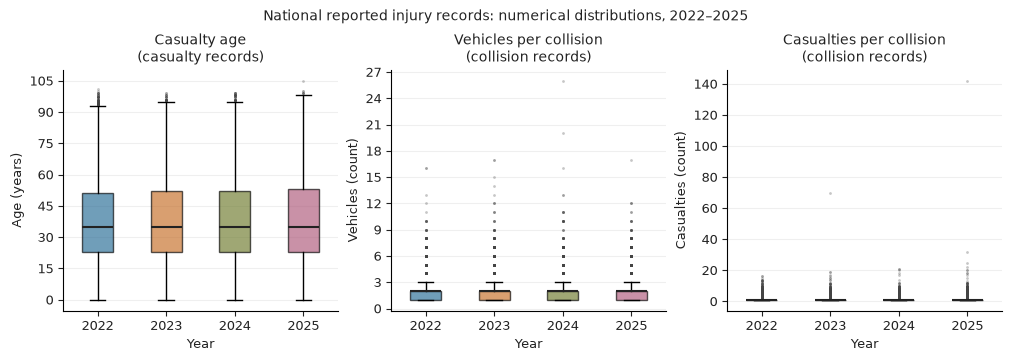

In [8]:
box_panels = (
    ("age_of_casualty", "Casualty age\n(casualty records)", "Age (years)"),
    ("number_of_vehicles", "Vehicles per collision\n(collision records)", "Vehicles (count)"),
    ("number_of_casualties", "Casualties per collision\n(collision records)", "Casualties (count)"),
)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5), layout="constrained")
for ax, (field, title, ylabel) in zip(axes, box_panels, strict=True):
    artists = ax.boxplot(
        [box_values[field][year] for year in YEARS],
        tick_labels=[str(year) for year in YEARS], whis=1.5, showfliers=True, patch_artist=True,
        medianprops={"color": "#222222", "linewidth": 1.5},
        flierprops={"marker": ".", "markersize": 2, "alpha": 0.3, "markeredgecolor": "#444444"},
    )
    for patch, year in zip(artists["boxes"], YEARS, strict=True):
        patch.set_facecolor(YEAR_COLORS[year])
        patch.set_alpha(0.65)
    ax.set(title=title, xlabel="Year", ylabel=ylabel)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis="y", alpha=0.2)
fig.suptitle("National reported injury records: numerical distributions, 2022–2025", fontsize=10)
plt.show()


**Findings:** median casualty age is 35 each year, and plot exclusions are 3,129, 2,926, 2,552 and 2,741 records. Vehicles per collision have median 2 and IQR 1, while casualties per collision have median 1 and IQR 0. The zero IQR classifies counts above one as fliers, while large observations compress the scale; neither finding alone justifies deleting events.

### 1.8 London pedestrian monthly patterns

**Figure 2 of 4:** compare monthly qualifying London collision counts using one line per year. Dates must match the source year, and counts are not adjusted for month length or pedestrian exposure. The figure supports exploration rather than causal or pooling conclusions.

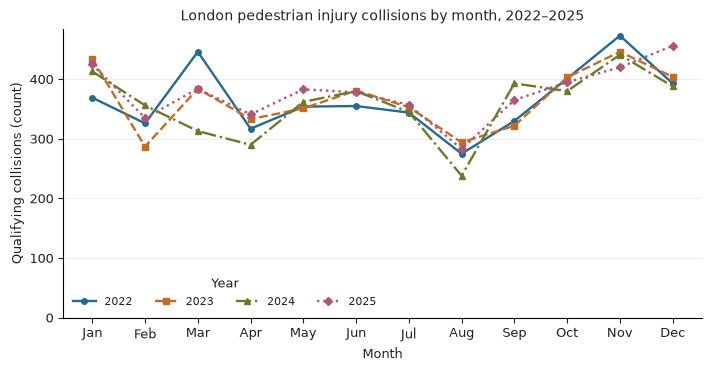

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.6), layout="constrained")
for year, marker, style in zip(YEARS, ("o", "s", "^", "D"), ("-", "--", "-.", ":"), strict=True):
    ax.plot(range(1, 13), london_monthly_counts.loc[year, list(range(1, 13))],
            label=str(year), color=YEAR_COLORS[year], marker=marker, linestyle=style,
            linewidth=1.7, markersize=4)
ax.set_xticks(range(1, 13), [calendar.month_abbr[month] for month in range(1, 13)])
ax.set(title="London pedestrian injury collisions by month, 2022–2025",
       xlabel="Month", ylabel="Qualifying collisions (count)", ylim=(0, None))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.legend(title="Year", ncols=4, frameon=False, loc="lower left", fontsize=8)
ax.grid(axis="y", alpha=0.2)
plt.show()


**Findings:** August is relatively low, while November peaks in 2022–2024 and December peaks in 2025. Annual London counts are 4,383, 4,392, 4,299 and 4,522. Month length, reporting and exposure have not been controlled, so these patterns do not establish causes.

### 1.9 London district counts and annual comparison

**Figure 3 of 4:** show the top ten districts by pooled qualifying collision count, with all 32 boroughs and City of London in the annual table. Use annual counts and geographic validity to assess candidate study areas. Counts do not measure individual pedestrian risk.

Qualifying pedestrian collisions: all 32 London boroughs plus City of London


year,district,2022,2023,2024,2025,total
district_code,,,,,,
E09000033,Westminster,283,336,310,321,1250
E09000008,Croydon,189,200,180,224,793
E09000022,Lambeth,210,203,164,174,751
E09000025,Newham,169,190,173,184,716
E09000030,Tower Hamlets,160,176,165,207,708
E09000005,Brent,183,155,188,165,691
E09000028,Southwark,174,181,148,177,680
E09000009,Ealing,166,147,188,171,672
E09000007,Camden,163,173,155,175,666


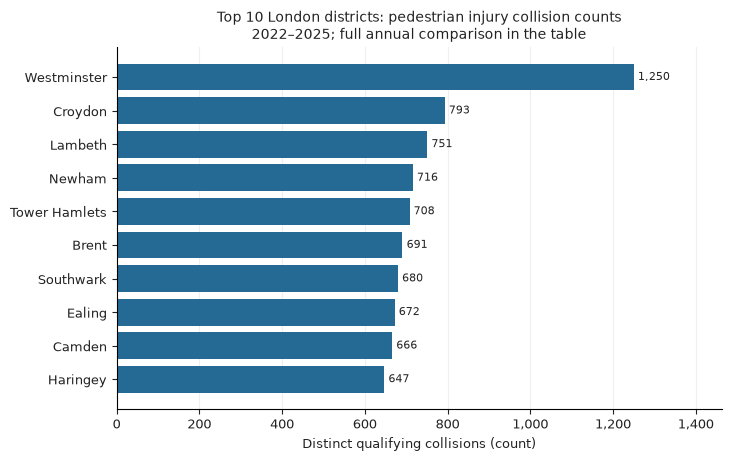

In [10]:
# All districts remain in the table; the compact chart shows the top ten only.
district_year_table = district_annual_counts.pivot(
    index="district_code", columns="year", values="pedestrian_collisions"
).reindex(index=list(london_names), columns=list(YEARS))
district_year_table["total"] = district_year_table[list(YEARS)].sum(axis=1)
district_year_table.insert(0, "district", district_year_table.index.map(london_names))
district_year_table = district_year_table.sort_values(["total", "district"], ascending=[False, True])
print("Qualifying pedestrian collisions: all 32 London boroughs plus City of London")
with pd.option_context("display.max_rows", 40, "display.max_columns", None):
    display(district_year_table)

top_districts = district_year_table.head(10).sort_values("total")
fig, ax = plt.subplots(figsize=(7.2, 4.5), layout="constrained")
bars = ax.barh(top_districts["district"], top_districts["total"], color=BLUE)
ax.bar_label(bars, labels=[f"{value:,}" for value in top_districts["total"]], padding=3, fontsize=8)
ax.set(title="Top 10 London districts: pedestrian injury collision counts\n2022–2025; full annual comparison in the table",
       xlabel="Distinct qualifying collisions (count)")
ax.set_xlim(0, max(float(top_districts["total"].max()) * 1.17, 1))
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
plt.show()


**Findings:** Westminster leads with 1,250 recorded collisions, followed by Croydon with 793 and Lambeth with 751. The annual table reveals variation within districts, such as Croydon ranging from 180 to 224. No borough is selected solely from this ranking, and contributions from area, exposure or reporting remain untested.

### 1.10 London coordinate quality and point map

**Figure 4 of 4:** plot all usable London source-grid coordinate pairs with equal axis scaling and no boundary overlay. The table reports missing/invalid pairs and within-year repeated locations. Visual darkness depends on overlap and is not a statistical hotspot measure.

**Method context:** [lecture map-design guidance](../references.md#r10) supports purposeful symbology; the [linked QGIS exercise](../references.md#r11) distinguishes visual density from statistical hotspots. Future membership checks will use [topological relationships](../references.md#r09); the present point map performs no boundary allocation.

Coordinate quality for qualifying London pedestrian collisions; denominator shown by year


,london_qualifying_collisions,missing_grid_pair_rows,invalid_nonblank_grid_pair_rows,mapped_collisions,missing_grid_pair_pct,invalid_nonblank_grid_pair_pct,records_sharing_coordinates_within_year,distinct_repeated_coordinate_pairs_within_year
year,,,,,,,,
2022,4383,0,0,4383,0.0,0.0,6,3
2023,4392,0,0,4392,0.0,0.0,2,1
2024,4299,0,0,4299,0.0,0.0,4,2
2025,4522,0,0,4522,0.0,0.0,4,2


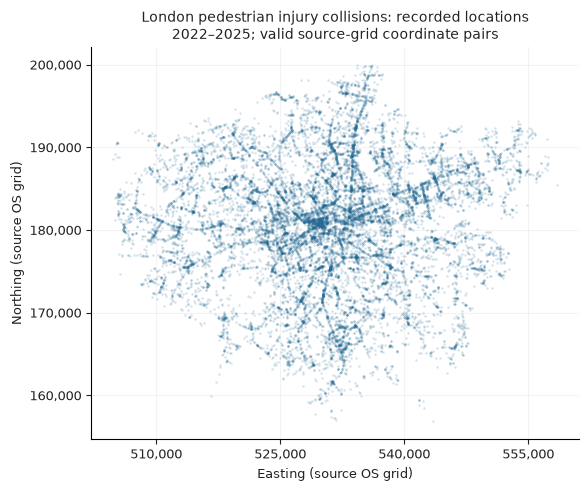

In [11]:
print("Coordinate quality for qualifying London pedestrian collisions; denominator shown by year")
with pd.option_context("display.max_columns", None):
    display(london_coordinate_checks.round(3))
if london_points.empty:
    raise ValueError("No qualifying London collisions have usable grid coordinates for the point map.")
assert london_points["collision_index"].is_unique
fig, ax = plt.subplots(figsize=(6.4, 4.8), layout="constrained")
ax.scatter(london_points["easting"], london_points["northing"],
           s=3, alpha=0.2, color=BLUE, linewidths=0)
ax.set_aspect("equal", adjustable="box")
ax.set(title="London pedestrian injury collisions: recorded locations\n2022–2025; valid source-grid coordinate pairs",
       xlabel="Easting (source OS grid)", ylabel="Northing (source OS grid)")
ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(alpha=0.15)
plt.show()


**Findings:** all 17,596 recorded-London collisions pass the broad grid-coordinate screen and appear in the map. Within-year repeated coordinates affect 6, 2, 4 and 4 records, which remain distinct events and are retained. The denser central pattern is descriptive; coordinate consistency, boundary membership and final spatial interpretation remain subject to validation.

## Task 2: Data preparation

Reuse the candidates selected in section 1.6 to add field-specific quality flags, audit the preparation and export derived files. Run Task 1 first in the same kernel; this section does not reload the raw annual files. Final borough membership and spatial concentration analysis remain later steps.

### 2.1 Cleaning decisions and spatial scope

Apply the rules below to retain auditable candidates and distinguish evaluated checks from unresolved spatial questions. Optional attributes never determine collision eligibility.

| Issue | Preparation rule | Later decision or validation |
| --- | --- | --- |
| Collision identity | Require nonblank, unique IDs within and across annual collision files. Preserve strings. | Investigate failures; never silently drop duplicate IDs. |
| Casualty identity and joins | Require complete unique collision/casualty-reference keys and matching collision-ID sets. | Halt on discrepancies before defining the candidate events. |
| Pedestrian eligibility | At least one class-3 casualty with severity 1, 2 or 3; check agreement with casualty type 0. Count the collision once. | Resolve unknown severity or contradictory pedestrian codes before selection. |
| Dates | Preserve raw date and add parsed date plus invalid/out-of-year flags. | Investigate flagged candidates before the final period filter. |
| Coordinate blanks or invalid values | Preserve original strings; derive numeric values and separate quality flags. | No guessed coordinates. Determine final spatial exclusions after validation and log them. |
| Recorded district | Distinguish blank, predates-code (-1), unrecognised, E09 London and EHEATHROW. | Geometry and an authoritative boundary decide final membership. Heathrow is not an unknown code. |
| Repeated coordinates | Flag valid pairs within-year and across the pooled period; retain distinct collision IDs. | Repeat for the final borough; shared positions do not imply duplicate events. |
| Age, sex and other context | Do not use optional attributes to define collision eligibility; age is loaded only for national EDA. | Decode missing codes only if those fields are analysed later. |
| Statistical outliers | Do not delete events because of an IQR flag. | Investigate separately if relevant; outlier status is not an eligibility rule. |
| London extent and boundary | Optional documented extent screens produce flags only; unset checks remain unknown. | Select a source/vintage and review boundary cases in QGIS. No rectangular screen defines borough membership. |

`local_authority_district = -1` means Code deprecated, so it is not used for borough selection. Enhanced/adjusted severity fields are unnecessary for this count-based task, although some have documented definitions.



### 2.2 Missing-value and spatial-quality flags

Preserve raw values while deriving date, district and coordinate-quality flags. Retain repeated valid grid pairs and distinguish within-year from pooled-national repetition. Unconfigured extents, coordinate consistency and borough membership remain unknown rather than false.

In [12]:
candidates["collision_date"] = pd.to_datetime(candidates["date"], format="%d/%m/%Y", errors="coerce")
candidates["flag_date_blank"] = candidates["date"].str.strip().eq("")
candidates["flag_date_invalid_nonblank"] = ~candidates["flag_date_blank"] & candidates["collision_date"].isna()
candidates["flag_date_outside_source_year"] = (
    candidates["collision_date"].notna()
    & candidates["collision_date"].dt.year.ne(candidates["source_file_year"])
)
candidates["flag_index_components_disagree"] = candidates["collision_index"].ne(
    candidates["collision_year"] + candidates["collision_ref_no"]
)
district = candidates["local_authority_ons_district"]
candidates["is_recorded_london"] = district.isin(london_labels)
candidates["is_heathrow"] = district.eq("EHEATHROW")
candidates["flag_district_blank"] = district.str.strip().eq("")
candidates["flag_district_predates_code"] = district.eq("-1")
candidates["flag_district_unrecognised"] = ~district.isin(valid_district_codes) & ~candidates["flag_district_blank"]

coordinate_columns = ["location_easting_osgr", "location_northing_osgr", "longitude", "latitude"]
for raw, numeric in zip(coordinate_columns, ["easting", "northing", "longitude_numeric", "latitude_numeric"], strict=True):
    candidates[numeric] = pd.to_numeric(candidates[raw], errors="coerce")
candidates["grid_crs"] = GRID_CRS
candidates["flag_grid_pair_blank"] = candidates[coordinate_columns[:2]].apply(
    lambda col: col.str.strip().eq("")
).any(axis=1)
grid_usable = candidates["easting"].between(0, 700000, inclusive="neither") & candidates["northing"].between(0, 1300000, inclusive="neither")
candidates["flag_grid_pair_invalid_nonblank"] = ~candidates["flag_grid_pair_blank"] & ~grid_usable
candidates["flag_lonlat_pair_blank"] = candidates[coordinate_columns[2:]].apply(
    lambda col: col.str.strip().eq("")
).any(axis=1)
lonlat_usable = (candidates["longitude_numeric"].between(-180, 180)
                 & candidates["latitude_numeric"].between(-90, 90)
                 & ~(candidates["longitude_numeric"].eq(0) & candidates["latitude_numeric"].eq(0)))
candidates["flag_lonlat_pair_invalid_nonblank"] = ~candidates["flag_lonlat_pair_blank"] & ~lonlat_usable

for name, keys in (("flag_grid_repeat_within_year", ["source_file_year", "easting", "northing"]),
                   ("flag_grid_repeat_pooled", ["easting", "northing"])):
    candidates[name] = False
    candidates.loc[grid_usable, name] = candidates.loc[grid_usable].duplicated(keys, keep=False)

def extent_flag(x: pd.Series, y: pd.Series, usable: pd.Series, bounds) -> pd.Series:
    result = pd.Series(pd.NA, index=x.index, dtype="boolean")
    if bounds is None:
        return result
    if len(bounds) != 4:
        raise ValueError("An extent needs four values: xmin, ymin, xmax, ymax.")
    xmin, ymin, xmax, ymax = bounds
    if not xmin < xmax or not ymin < ymax:
        raise ValueError("Invalid extent ordering.")
    inside = x.between(xmin, xmax) & y.between(ymin, ymax)
    result.loc[usable] = ~inside.loc[usable]
    return result

candidates["flag_outside_london_grid_extent"] = extent_flag(
    candidates["easting"], candidates["northing"], grid_usable, LONDON_GRID_EXTENT
)
candidates["flag_outside_london_lonlat_extent"] = extent_flag(
    candidates["longitude_numeric"], candidates["latitude_numeric"], lonlat_usable, LONDON_LONLAT_EXTENT
)
candidates["flag_grid_lonlat_disagree"] = pd.Series(pd.NA, index=candidates.index, dtype="boolean")
candidates["flag_inside_selected_borough"] = pd.Series(pd.NA, index=candidates.index, dtype="boolean")
candidates["spatial_validation_status"] = "pending_crs_consistency_and_boundary_checks"
candidates = candidates.sort_values(["source_file_year", "collision_index"]).reset_index(drop=True)


**Preparation note:** flags are created without deleting or imputing records. Their evaluated counts and unperformed checks are displayed in the audit below.

### 2.3 Preparation audit

Summarise selection and flags by year, pooled period and national/London/Heathrow scope. Use `checked_rows` as the flag denominator and preserve `not_checked` when no evaluation occurred. Repeated-coordinate flags refer to all national candidates, even when their counts are displayed for the recorded-London subset.

In [13]:
flag_columns = [column for column in candidates if column.startswith("flag_")]
for period in [*(str(year) for year in YEARS), "pooled"]:
    period_rows = candidates if period == "pooled" else candidates.loc[candidates["source_file_year"].eq(int(period))]
    scopes = {"all_qualifying": period_rows,
              "recorded_london": period_rows.loc[period_rows["is_recorded_london"]],
              "heathrow": period_rows.loc[period_rows["is_heathrow"]]}
    for scope, subset in scopes.items():
        log_rows.append({"period": period, "scope": scope, "metric": "candidate_rows",
                         "count": len(subset), "checked_rows": pd.NA, "status": "counted"})
        for flag in flag_columns:
            checked = int(subset[flag].notna().sum())
            log_rows.append({"period": period, "scope": scope, "metric": flag,
                             "count": int(subset[flag].sum()) if checked else pd.NA,
                             "checked_rows": checked,
                             "status": "checked" if checked else "not_checked"})
preparation_log = pd.DataFrame(log_rows)
print("Selection counts")
display(selection_log.loc[selection_log["status"].eq("counted")].pivot(
    index="period", columns="metric", values="count"
))
print("Pooled recorded-London quality flags; repeat flags refer to all national candidates")
display(preparation_log.loc[
    preparation_log["period"].eq("pooled") & preparation_log["scope"].eq("recorded_london")
])
print("Candidate records (first five; not a final cleaned dataset)")
display(candidates.head())


Selection counts


metric,heathrow_qualifying_rows,nonqualifying_collision_rows,pedestrian_casualty_rows,qualifying_collision_rows,recorded_london_qualifying_rows,source_casualty_rows,source_collision_rows
period,,,,,,,
2022,2,87421,19327,18583,4383,135480,106004
2023,2,85733,19263,18525,4392,132977,104258
2024,6,82468,19176,18459,4299,128272,100927
2025,7,82410,19978,19115,4522,127883,101525


Pooled recorded-London quality flags; repeat flags refer to all national candidates


,period,scope,metric,count,checked_rows,status
266,pooled,recorded_london,candidate_rows,17596,<NA>,counted
267,pooled,recorded_london,flag_date_blank,0,17596,checked
268,pooled,recorded_london,flag_date_invalid_nonblank,0,17596,checked
269,pooled,recorded_london,flag_date_outside_source_year,0,17596,checked
270,pooled,recorded_london,flag_index_components_disagree,0,17596,checked
271,pooled,recorded_london,flag_district_blank,0,17596,checked
272,pooled,recorded_london,flag_district_predates_code,0,17596,checked
273,pooled,recorded_london,flag_district_unrecognised,0,17596,checked
274,pooled,recorded_london,flag_grid_pair_blank,0,17596,checked
275,pooled,recorded_london,flag_grid_pair_invalid_nonblank,0,17596,checked


Candidate records (first five; not a final cleaned dataset)


,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,date,local_authority_ons_district,source_file_year,...,flag_grid_pair_invalid_nonblank,flag_lonlat_pair_blank,flag_lonlat_pair_invalid_nonblank,flag_grid_repeat_within_year,flag_grid_repeat_pooled,flag_outside_london_grid_extent,flag_outside_london_lonlat_extent,flag_grid_lonlat_disagree,flag_inside_selected_borough,spatial_validation_status
0,2022010352596,2022,010352596,539501,178262,0.007763,51.486112,01/01/2022,E09000011,2022,...,False,False,False,False,False,<NA>,<NA>,<NA>,<NA>,pending_crs_consistency_and_boundary_checks
1,2022010352600,2022,010352600,534597,190727,-0.05806,51.599313,01/01/2022,E09000014,2022,...,False,False,False,False,False,<NA>,<NA>,<NA>,<NA>,pending_crs_consistency_and_boundary_checks
2,2022010352605,2022,010352605,534094,182549,-0.068434,51.525943,01/01/2022,E09000030,2022,...,False,False,False,False,False,<NA>,<NA>,<NA>,<NA>,pending_crs_consistency_and_boundary_checks
3,2022010352616,2022,010352616,538111,177157,-0.012675,51.476523,01/01/2022,E09000011,2022,...,False,False,False,False,False,<NA>,<NA>,<NA>,<NA>,pending_crs_consistency_and_boundary_checks
4,2022010352624,2022,010352624,533874,191438,-0.068221,51.605874,01/01/2022,E09000014,2022,...,False,False,False,False,False,<NA>,<NA>,<NA>,<NA>,pending_crs_consistency_and_boundary_checks


**Findings:** no evaluated date, ID-composition, district-code or coordinate-range problems are flagged among the 17,596 recorded-London candidates. Repeated-grid flags affect 16 London-coded records within years and 66 over the pooled national comparison, and these events are retained. Extent, coordinate-consistency and borough-membership checks remain `not_checked`, so final spatial eligibility is unresolved.

### 2.4 Derived exports

Write `pedestrian_collision_candidates.csv` and `preparation_log.csv` to `OUTPUT_DIR`, replacing only those derived exports on a rerun. Retain national candidates with quality flags and recorded-London/Heathrow indicators; the code-based London view is not final membership. CSV does not embed a CRS, so use documented EPSG:27700 for numeric grid coordinates in QGIS and confirm the geographic datum before transforming longitude/latitude.

In [14]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
candidate_output = OUTPUT_DIR / "pedestrian_collision_candidates.csv"
log_output = OUTPUT_DIR / "preparation_log.csv"
raw_paths = {(DATA_DIR / name).resolve() for name in required_files}
if candidate_output.resolve() in raw_paths or log_output.resolve() in raw_paths:
    raise ValueError("Output path conflicts with a raw input.")
if not candidates["collision_index"].is_unique:
    raise ValueError("Refusing export: candidate collision IDs are not unique.")
candidates.to_csv(candidate_output, index=False, date_format="%Y-%m-%d", na_rep="")
preparation_log.to_csv(log_output, index=False, na_rep="")
print("Exported candidate rows:", len(candidates))
print("Candidate file:", candidate_output)
print("Preparation log:", log_output)


Exported candidate rows: 74682
Candidate file: ../data/derived/pedestrian_collision_candidates.csv
Preparation log: ../data/derived/preparation_log.csv


**Findings:** the saved export reports 74,682 candidate rows, and both derived files exist. The candidate header contains 38 columns, with raw values, provenance and quality flags retained. No imputation or spatial exclusions were applied; final borough membership still requires boundary validation.